<a href="https://colab.research.google.com/github/sami01979/ai_text_detection/blob/main/electra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q datasets transformers accelerate

In [ ]:
import re, os, numpy as np, pandas as pd
from datasets import load_dataset
from google.colab import drive
drive.mount('/content/drive')
D = "/content/drive/MyDrive/thesis_data/"

ds = load_dataset("yaful/MAGE")
print(ds)    #

def clean(t):
    t = re.sub(r"https?://\S+", "", str(t))
    return re.sub(r"\s+", " ", t).strip()

def build(split, n_per_class, seed, exclude=frozenset()):
    df = split.to_pandas()
    df["text"] = df["text"].apply(clean)
    df["ai"] = 1 - df["label"].astype(int)
    df = df[df.text.str.split().str.len().between(30, 400)].drop_duplicates("text")
    df = df[~df.text.isin(exclude)]
    print(f"  available per class after filtering: {df.ai.value_counts().to_dict()}")
    n = min(n_per_class, df.ai.value_counts().min())
    out = pd.concat([df[df.ai == c].sample(n, random_state=seed) for c in (0, 1)])
    out = out.drop(columns=["label"]).rename(columns={"ai": "label"})
    return out.sample(frac=1, random_state=seed).reset_index(drop=True)

test  = build(ds["test"], 7500, 1)
val   = build(ds["validation"], 7500, 2, exclude=set(test.text))
train = build(ds["train"], 60000, 3, exclude=set(test.text) | set(val.text))

for name, d in [("train", train), ("val", val), ("test", test)]:
    print(name, len(d), d.label.value_counts().to_dict())
print("overlap train/test:", len(set(train.text) & set(test.text)), "| train/val:", len(set(train.text) & set(val.text)))


src_col = [c for c in train.columns if c not in ("text", "label")]
print("source column:", src_col)
if src_col:
    print("label=1 rows with 'machine' in source:", train[train.label == 1][src_col[0]].astype(str).str.contains("machine").mean())

train.to_csv(D + "mage_train.csv", index=False)
val.to_csv(D + "mage_val.csv", index=False)
test.to_csv(D + "mage_test.csv", index=False)
print("saved")

Mounted at /content/drive


README.md:   0%|          | 0.00/1.93k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B /  404MB            

train.csv: downloading bytes:           |  0.00B            

valid.csv: reconstructing file:   0%|          |  0.00B / 72.3MB            

...

test_ood_set_gpt_para.csv:   0%|          | 0.00/3.61M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/319071 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/56792 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/60743 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 319071
    })
    validation: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 56792
    })
    test: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 60743
    })
})
  available per class after filtering: {1: 24604, 0: 22645}
  available per class after filtering: {1: 22310, 0: 21986}
  available per class after filtering: {1: 181129, 0: 76193}
train 120000 {0: 60000, 1: 60000}
val 15000 {1: 7500, 0: 7500}
test 15000 {1: 7500, 0: 7500}
overlap train/test: 0 | train/val: 0
source column: ['src']
label=1 rows with 'machine' in source: 1.0
saved


In [ ]:
!pip install -q transformers datasets accelerate

In [ ]:
import os, numpy as np, pandas as pd, torch
from google.colab import drive
drive.mount('/content/drive')
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

assert torch.cuda.is_available(), "NO GPU - change runtime type to T4 first"

D   = "/content/drive/MyDrive/thesis_data/"
OUT = "/content/drive/MyDrive/thesis_run_electra"
os.makedirs(OUT, exist_ok=True)
MODEL, MAX_LEN = "google/electra-base-discriminator", 256

train    = pd.read_csv(D + "mage_train.csv")
val_full = pd.read_csv(D + "mage_val.csv")
val_fast = val_full.sample(4000, random_state=42)
print(len(train), len(val_full), train.label.value_counts().to_dict())

tok = AutoTokenizer.from_pretrained(MODEL)

def prep(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    ds = ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN), batched=True)
    return ds.remove_columns(["text"])

tr, va_fast = prep(train), prep(val_fast)
model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=2).float()

def metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1}

args = TrainingArguments(
    output_dir=OUT,
    num_train_epochs=2,
    per_device_train_batch_size=16,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=64,
    learning_rate=3e-5,
    weight_decay=0.01,
    warmup_steps=300,
    eval_strategy="steps", eval_steps=1000,
    save_strategy="steps", save_steps=1000,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    fp16=True,
    logging_steps=200,
    report_to="none",
)

trainer = Trainer(model=model, args=args, train_dataset=tr, eval_dataset=va_fast,
                  processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=metrics)

has_ckpt = any(d.startswith("checkpoint") for d in os.listdir(OUT))
trainer.train(resume_from_checkpoint=True if has_ckpt else None)

final = OUT + "/final_model_electra_mage"
trainer.save_model(final)
tok.save_pretrained(final)
print("saved:", os.listdir(final))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
120000 15000 {0: 60000, 1: 60000}


config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved: ['config.json', 'model.safetensors', 'tokenizer_config.json', 'tokenizer.json', 'training_args.bin']


In [1]:
!pip install -q transformers datasets accelerate

In [3]:
import numpy as np, pandas as pd, torch, gc
from google.colab import drive
drive.mount('/content/drive')
from transformers import AutoTokenizer, AutoModelForSequenceClassification

assert torch.cuda.is_available(), "NO GPU - set the runtime to T4 first"
D = "/content/drive/MyDrive/thesis_data/"
PATHS = {
    "RoBERTa":      "/content/drive/MyDrive/final_model_v1",
    "DeBERTa":      "/content/drive/MyDrive/thesis_run_deberta/final_model_deberta_v1",
    "ELECTRA-MAGE": "/content/drive/MyDrive/thesis_run_electra/final_model_electra_mage",
}
FILES = {"merged_val": "val.csv", "merged_test": "test.csv", "mage_val": "mage_val.csv", "mage_test": "mage_test.csv"}
sets = {k: pd.read_csv(D + f) for k, f in FILES.items()}
print({k: len(v) for k, v in sets.items()})

def probs(tok, model, texts, bs=64):
    order = np.argsort([len(t) for t in texts])
    out = np.zeros(len(texts))
    for i in range(0, len(texts), bs):
        idx = order[i:i + bs]
        enc = tok([texts[j] for j in idx], truncation=True, max_length=256,
                  padding=True, return_tensors="pt").to("cuda")
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            out[idx] = torch.softmax(model(**enc).logits.float(), dim=-1)[:, 1].cpu().numpy()
    return out

names = list(PATHS)
P = {k: np.zeros((len(v), len(names))) for k, v in sets.items()}
for j, n in enumerate(names):
    print("scoring with", n, "...")
    tok = AutoTokenizer.from_pretrained(PATHS[n])
    model = AutoModelForSequenceClassification.from_pretrained(PATHS[n]).float().cuda().eval()
    for k, v in sets.items():
        P[k][:, j] = probs(tok, model, v.text.tolist())
    del model; gc.collect(); torch.cuda.empty_cache()
    np.savez("/content/drive/MyDrive/triple_probs.npz", **P)
print("saved")

Mounted at /content/drive
{'merged_val': 9951, 'merged_test': 9952, 'mage_val': 15000, 'mage_test': 15000}
scoring with RoBERTa ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

scoring with DeBERTa ...


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

scoring with ELECTRA-MAGE ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

saved


In [4]:
import numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

D = "/content/drive/MyDrive/thesis_data/"
names = ["RoBERTa", "DeBERTa", "ELECTRA-MAGE"]
FILES = {"merged_val": "val.csv", "merged_test": "test.csv", "mage_val": "mage_val.csv", "mage_test": "mage_test.csv"}
S = {k: pd.read_csv(D + f) for k, f in FILES.items()}
Y = {k: v.label.values for k, v in S.items()}
P = dict(np.load("/content/drive/MyDrive/triple_probs.npz"))
ths = np.concatenate([np.arange(0.05, 0.95, 0.01), np.arange(0.95, 0.9995, 0.001)])

def best_t(p, y):
    return ths[int(np.argmax([accuracy_score(y, p >= t) for t in ths]))]

tuned = {(ds, i): best_t(P[ds + "_val"][:, i], Y[ds + "_val"]) for ds in ["merged", "mage"] for i in range(3)}
res = {}

print("=== 1. Single models ===")
rows = []
for ds in ["merged", "mage"]:
    y = Y[ds + "_test"]
    for i, n in enumerate(names):
        pt, t = P[ds + "_test"][:, i], tuned[(ds, i)]
        rows.append({"test set": ds, "model": n, "tuned thr": round(t, 3), "acc@0.5": round(accuracy_score(y, pt >= .5), 4),
                     "acc@tuned": round(accuracy_score(y, pt >= t), 4), "AUC": round(roc_auc_score(y, pt), 4)})
        res.setdefault(n + " @0.5", {})[ds] = accuracy_score(y, pt >= .5)
        res.setdefault(n + " @tuned", {})[ds] = accuracy_score(y, pt >= t)
print(pd.DataFrame(rows).to_string(index=False))

print("\n=== 2. Majority vote and agreement ===")
for mode in ["0.5", "tuned"]:
    for ds in ["merged", "mage"]:
        X, y = P[ds + "_test"], Y[ds + "_test"]
        th = np.array([0.5] * 3) if mode == "0.5" else np.array([tuned[(ds, i)] for i in range(3)])
        votes = (X >= th).sum(axis=1); maj = votes >= 2; unan = (votes == 0) | (votes == 3)
        res.setdefault(f"VOTE @{mode}", {})[ds] = accuracy_score(y, maj)
        print(f"[{mode:5s}] {ds:6s}: vote acc {accuracy_score(y, maj):.4f} | all-3-agree {unan.mean():.1%} -> acc {accuracy_score(y[unan], maj[unan]):.4f}"
              f" | split decisions {(~unan).mean():.1%} -> acc {accuracy_score(y[~unan], maj[~unan]):.4f}")

print("\n=== 3. Stacked meta-model (fit on both validation sets, scored on both test sets) ===")
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
Xv = np.vstack([logit(P["merged_val"]), logit(P["mage_val"])]); yv = np.concatenate([Y["merged_val"], Y["mage_val"]])
meta = LogisticRegression(max_iter=1000).fit(Xv, yv)
print("weights:", dict(zip(names, np.round(meta.coef_[0], 3))))
for ds in ["merged", "mage"]:
    ps = meta.predict_proba(logit(P[ds + "_test"]))[:, 1]; y = Y[ds + "_test"]
    res.setdefault("STACK", {})[ds] = accuracy_score(y, ps >= .5)
    print(f"{ds:6s}: acc {accuracy_score(y, ps >= .5):.4f} | F1 {f1_score(y, ps >= .5):.4f} | AUC {roc_auc_score(y, ps):.4f}")

print("\n=== 4. Summary: accuracy on both datasets ===")
sm = pd.DataFrame(res).T.round(4)
sm["mean"] = sm.mean(axis=1).round(4); sm["worst"] = sm[["merged", "mage"]].min(axis=1)
print(sm.sort_values("mean", ascending=False).to_string())

print("\n=== 5. Accuracy per MAGE domain (test set, threshold 0.5) ===")
mt = S["mage_test"]; X, y = P["mage_test"], Y["mage_test"]
d = pd.DataFrame({"domain": mt["src"].astype(str).str.split("_").str[0]})
for i, n in enumerate(names): d[n] = ((X[:, i] >= .5) == y).astype(float)
d["VOTE"] = (((X >= .5).sum(axis=1) >= 2) == y).astype(float)
print(d.groupby("domain").mean().round(3).to_string())
print("\ntexts per domain:", d.domain.value_counts().to_dict())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== 1. Single models ===
test set        model  tuned thr  acc@0.5  acc@tuned    AUC
  merged      RoBERTa      0.975   0.9340     0.9438 0.9894
  merged      DeBERTa      0.997   0.9424     0.9642 0.9940
  merged ELECTRA-MAGE      0.999   0.8497     0.8969 0.9568
    mage      RoBERTa      0.976   0.8489     0.8856 0.9574
    mage      DeBERTa      0.997   0.8541     0.9139 0.9666
    mage ELECTRA-MAGE      0.997   0.8574     0.9049 0.9663

=== 2. Majority vote and agreement ===
[0.5  ] merged: vote acc 0.9438 | all-3-agree 83.1% -> acc 0.9705 | split decisions 16.9% -> acc 0.8124
[0.5  ] mage  : vote acc 0.8653 | all-3-agree 83.8% -> acc 0.9149 | split decisions 16.2% -> acc 0.6091
[tuned] merged: vote acc 0.9604 | all-3-agree 87.4% -> acc 0.9830 | split decisions 12.6% -> acc 0.8034
[tuned] mage  : vote acc 0.9171 | all-3-agree 86.2% -> acc 0.9568 | split 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


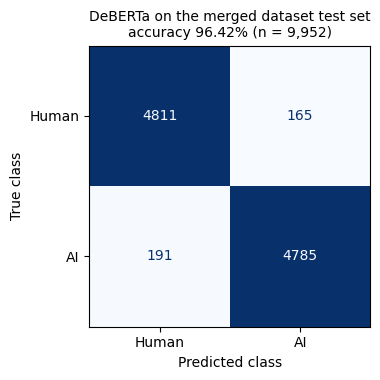

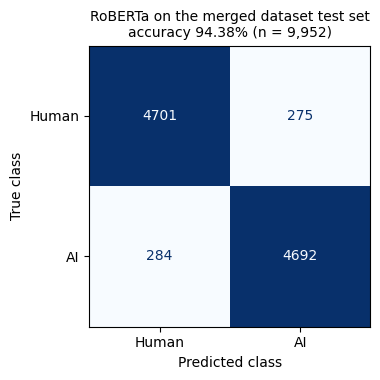

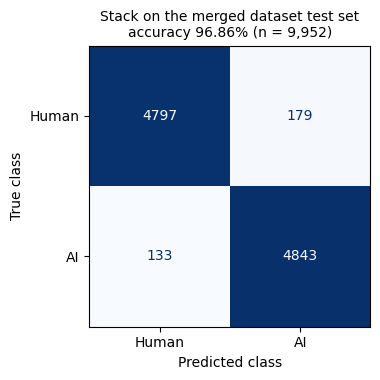

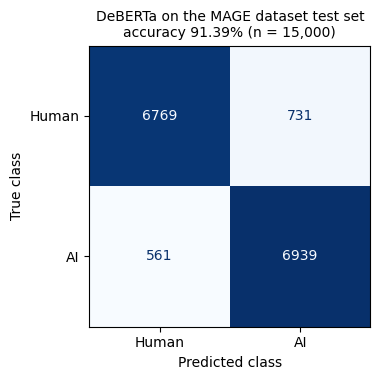

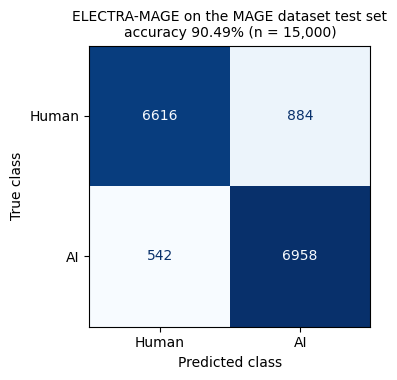

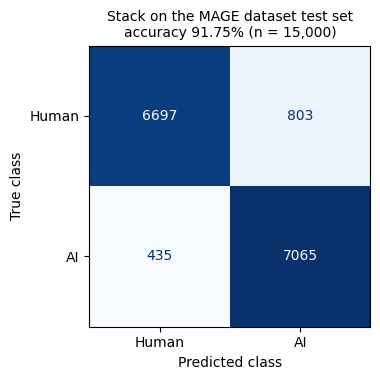

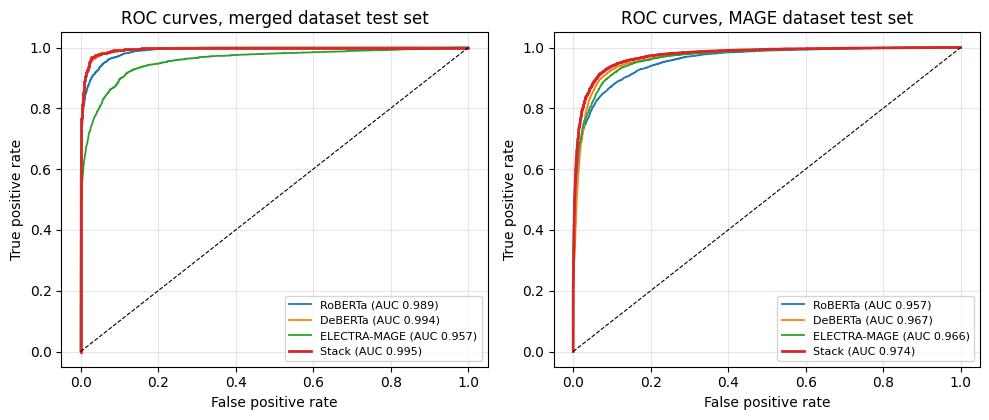

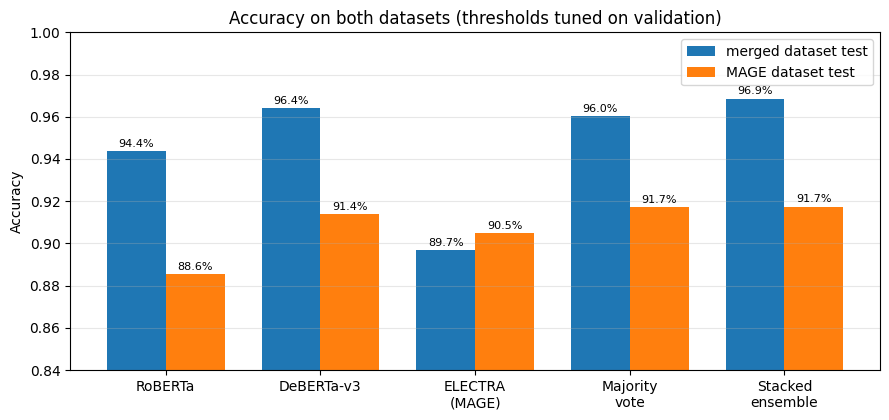

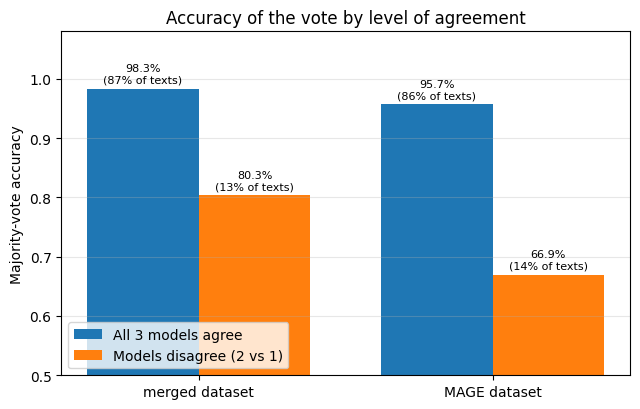

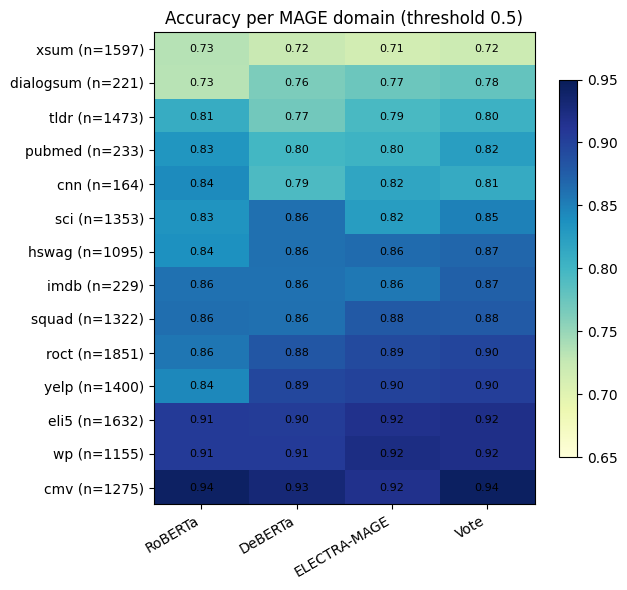

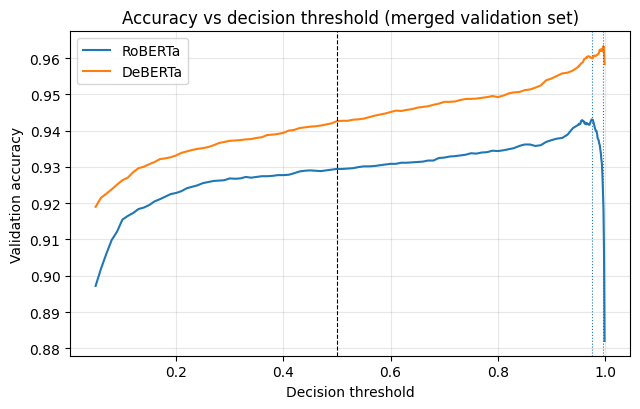

saved: ['accuracy_comparison.png', 'agreement_analysis.png', 'cm_DeBERTa_mage.png', 'cm_DeBERTa_merged.png', 'cm_ELECTRA-MAGE_mage.png', 'cm_RoBERTa_merged.png', 'cm_Stack_mage.png', 'cm_Stack_merged.png', 'per_domain_accuracy.png', 'roc_curves.png', 'threshold_curve.png']


In [5]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

D = "/content/drive/MyDrive/thesis_data/"
OUT = "/content/drive/MyDrive/thesis_figures/"
os.makedirs(OUT, exist_ok=True)
names = ["RoBERTa", "DeBERTa", "ELECTRA-MAGE"]
FILES = {"merged_val": "val.csv", "merged_test": "test.csv", "mage_val": "mage_val.csv", "mage_test": "mage_test.csv"}
S = {k: pd.read_csv(D + f) for k, f in FILES.items()}
Y = {k: v.label.values for k, v in S.items()}
P = dict(np.load("/content/drive/MyDrive/triple_probs.npz"))
ths = np.concatenate([np.arange(0.05, 0.95, 0.01), np.arange(0.95, 0.9995, 0.001)])
DS_NAME = {"merged": "merged dataset", "mage": "MAGE dataset"}

def best_t(p, y):
    return ths[int(np.argmax([accuracy_score(y, p >= t) for t in ths]))]
tuned = {(ds, i): best_t(P[ds + "_val"][:, i], Y[ds + "_val"]) for ds in ["merged", "mage"] for i in range(3)}

def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
Xv = np.vstack([logit(P["merged_val"]), logit(P["mage_val"])])
yv = np.concatenate([Y["merged_val"], Y["mage_val"]])
meta = LogisticRegression(max_iter=1000).fit(Xv, yv)

def prob(system, ds):
    X = P[ds + "_test"]
    if system in names: return X[:, names.index(system)]
    return meta.predict_proba(logit(X))[:, 1]

def predict(system, ds):
    X = P[ds + "_test"]
    if system in names:
        i = names.index(system); return (X[:, i] >= tuned[(ds, i)]).astype(int)
    if system == "Vote":
        th = np.array([tuned[(ds, i)] for i in range(3)]); return ((X >= th).sum(1) >= 2).astype(int)
    return (prob("Stack", ds) >= 0.5).astype(int)


def save_cm(system, ds):
    y = Y[ds + "_test"]; pred = predict(system, ds)
    fig, ax = plt.subplots(figsize=(4.3, 3.9))
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["Human", "AI"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{system} on the {DS_NAME[ds]} test set\naccuracy {accuracy_score(y, pred):.2%} (n = {len(y):,})", fontsize=10)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    fig.tight_layout(); fig.savefig(OUT + f"cm_{system}_{ds}.png", dpi=200); plt.show()
for system, ds in [("DeBERTa", "merged"), ("RoBERTa", "merged"), ("Stack", "merged"),
                   ("DeBERTa", "mage"), ("ELECTRA-MAGE", "mage"), ("Stack", "mage")]:
    save_cm(system, ds)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, ds in zip(axes, ["merged", "mage"]):
    y = Y[ds + "_test"]
    for system in names + ["Stack"]:
        p = prob(system, ds); fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, lw=2 if system == "Stack" else 1.3, label=f"{system} (AUC {roc_auc_score(y, p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"ROC curves, {DS_NAME[ds]} test set"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right", fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT + "roc_curves.png", dpi=200); plt.show()


systems = ["RoBERTa", "DeBERTa", "ELECTRA-MAGE", "Vote", "Stack"]
acc = {ds: [accuracy_score(Y[ds + "_test"], predict(s, ds)) for s in systems] for ds in ["merged", "mage"]}
x, w = np.arange(len(systems)), 0.38
fig, ax = plt.subplots(figsize=(9, 4.3))
for k, ds in enumerate(["merged", "mage"]):
    bars = ax.bar(x + (k - 0.5) * w, acc[ds], w, label=f"{DS_NAME[ds]} test")
    for b, v in zip(bars, acc[ds]): ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.1%}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(["RoBERTa", "DeBERTa-v3", "ELECTRA\n(MAGE)", "Majority\nvote", "Stacked\nensemble"])
ax.set_ylim(0.84, 1.0); ax.set_ylabel("Accuracy"); ax.set_title("Accuracy on both datasets (thresholds tuned on validation)")
ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(OUT + "accuracy_comparison.png", dpi=200); plt.show()


fig, ax = plt.subplots(figsize=(6.5, 4.2)); lab, a_all, a_split, share = [], [], [], []
for ds in ["merged", "mage"]:
    y = Y[ds + "_test"]; X = P[ds + "_test"]
    votes = (X >= np.array([tuned[(ds, i)] for i in range(3)])).sum(1); maj = votes >= 2; un = (votes == 0) | (votes == 3)
    lab.append(DS_NAME[ds]); a_all.append(accuracy_score(y[un], maj[un])); a_split.append(accuracy_score(y[~un], maj[~un])); share.append(un.mean())
x, w = np.arange(2), 0.38
b1 = ax.bar(x - w / 2, a_all, w, label="All 3 models agree"); b2 = ax.bar(x + w / 2, a_split, w, label="Models disagree (2 vs 1)")
for b, v, s in zip(b1, a_all, share): ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.1%}\n({s:.0%} of texts)", ha="center", fontsize=8)
for b, v, s in zip(b2, a_split, share): ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.1%}\n({1 - s:.0%} of texts)", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_ylim(0.5, 1.08); ax.set_ylabel("Majority-vote accuracy")
ax.set_title("Accuracy of the vote by level of agreement"); ax.legend(loc="lower left"); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(OUT + "agreement_analysis.png", dpi=200); plt.show()

mt = S["mage_test"]; X, y = P["mage_test"], Y["mage_test"]
d = pd.DataFrame({"domain": mt["src"].astype(str).str.split("_").str[0]})
for i, n in enumerate(names): d[n] = ((X[:, i] >= .5) == y).astype(float)
d["Vote"] = (((X >= .5).sum(1) >= 2) == y).astype(float)
g = d.groupby("domain").mean(); cnt = d.domain.value_counts()
g = g.loc[g.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(g.values, cmap="YlGnBu", vmin=0.65, vmax=0.95, aspect="auto")
ax.set_xticks(range(g.shape[1])); ax.set_xticklabels(g.columns, rotation=30, ha="right")
ax.set_yticks(range(g.shape[0])); ax.set_yticklabels([f"{k} (n={cnt[k]})" for k in g.index])
for r in range(g.shape[0]):
    for c in range(g.shape[1]): ax.text(c, r, f"{g.values[r, c]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Accuracy per MAGE domain (threshold 0.5)"); fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); fig.savefig(OUT + "per_domain_accuracy.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for i, n in enumerate(names[:2]):
    a = [accuracy_score(Y["merged_val"], P["merged_val"][:, i] >= t) for t in ths]
    ax.plot(ths, a, label=n); ax.axvline(tuned[("merged", i)], ls=":", lw=0.8)
ax.axvline(0.5, color="k", ls="--", lw=0.8)
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Validation accuracy"); ax.set_title("Accuracy vs decision threshold (merged validation set)")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); fig.savefig(OUT + "threshold_curve.png", dpi=200); plt.show()

print("saved:", sorted(os.listdir(OUT)))